In [ ]:
# fish_logistic.csv 파일을 이용하여 분류모델을 만들고
#  242.0 25.4 30.0 11.52 4.0200
# 290.0 26.3 31.2 12.48 4.3056
# 무게, 길이, 대각선, 높이, 넓이를 입력받아
# 분류생선과 확률을 출력하시오.
# 분류생선은 98.123%의 확률로 bream 판별됩니다.

In [36]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus']=False

import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.linear_model import LinearRegression,LogisticRegression
from sklearn.preprocessing import PolynomialFeatures,StandardScaler  # 다항특성 자동생성, # 정규화클래스
from sklearn.linear_model import Ridge, Lasso
from sklearn.metrics import mean_absolute_error   # 평균절대값오차 오차범위
from sklearn.model_selection import train_test_split
from scipy.special import expit, softmax # expit는 이진분류함수, softmax는 다중분류함수 => 0~1사이의 숫자로 변환시키는 기능

In [37]:
df = pd.read_csv('../data/fish_logistic.csv')
df.head(2)

,Species,Weight,Length,Diagonal,Height,Width
0,Bream,242.0,25.4,30.0,11.52,4.0200
1,Bream,290.0,26.3,31.2,12.48,4.3056


In [38]:
data = df[df.columns[1:]].values
label = df['Species'].values

In [39]:
label.unique()

<StringArray>
['Bream', 'Roach', 'Whitefish', 'Parkki', 'Perch', 'Pike', 'Smelt']
Length: 7, dtype: str

In [40]:
train_data,test_data,train_label,test_label = \
train_test_split(data,label,random_state=42)

In [41]:
ss = StandardScaler()
ss.fit(train_data,train_label)
train_scaled = ss.transform(train_data)
test_scaled = ss.transform(test_data)

In [42]:
cc = [0.001,0.01,0.1,1,10,100]
train_score = []
test_score = []
for c in cc:
    lr = LogisticRegression(C=c, max_iter=1000)
    lr.fit(train_scaled,train_label)

    train_score.append(lr.score(train_scaled,train_label))
    test_score.append(lr.score(test_scaled,test_label))

    print('c:',c)
    print('train_score:',train_score[-1])
    print('test_score:',test_score[-1])

best_index = np.argmax(test_score)
best_c = cc[best_index]
best_score = test_score[best_index]
print(f'최적c: {best_c}, best_score:{best_score}')

c: 0.001
train_score: 0.3697478991596639
test_score: 0.3
c: 0.01
train_score: 0.4369747899159664
test_score: 0.4
c: 0.1
train_score: 0.7058823529411765
test_score: 0.775
c: 1
train_score: 0.8067226890756303
test_score: 0.85
c: 10
train_score: 0.9159663865546218
test_score: 0.925
c: 100
train_score: 0.9831932773109243
test_score: 0.925
최적c: 10, best_score:0.925


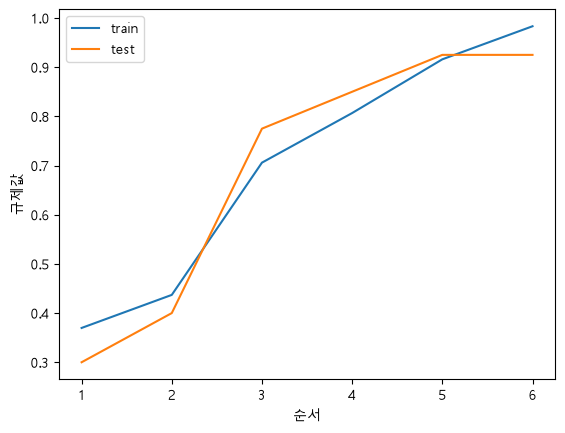

In [43]:
# C의 규제 선그래프
list1 = [1,2,3,4,5,6]
plt.plot(list1,train_score)
plt.plot(list1,test_score)
plt.xlabel('순서')
plt.ylabel('규제값')
plt.legend(['train','test'])
plt.show()

In [44]:
# 입력값 5개까지를 분류예측하여 각 분류별 확률값을 나타낼 것

In [45]:
proba = lr.predict_proba(test_scaled[:5])
decisions = lr.decision_function(test_scaled[:5])
soft1 = softmax(decisions,axis=1)
np.round(soft1,decimals=3)

array([[0.   , 0.002, 0.964, 0.   , 0.032, 0.001, 0.001],
       [0.   , 0.   , 0.012, 0.   , 0.001, 0.986, 0.   ],
       [0.   , 0.   , 0.005, 0.805, 0.001, 0.189, 0.   ],
       [0.001, 0.025, 0.133, 0.001, 0.723, 0.   , 0.116],
       [0.   , 0.   , 0.971, 0.   , 0.027, 0.001, 0.   ]])

In [46]:
# 242.0 25.4 30.0 11.52 4.0200 값을 입력해서 분류 예측하고, 각 분류별 확률을 도출

In [47]:
indata = '32,13.7,14.7,3.528,1.9992'
indata = indata.split(',')
indata = list(map(float,indata))

In [48]:

indata_scaled = ss.transform([indata])
lr = LogisticRegression(C=best_c, max_iter=1000)
lr.fit(train_scaled,train_label)

,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",10
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in

In [49]:
predict = lr.predict(indata_scaled)
predict

array(['Perch'], dtype=object)

In [50]:
proba = lr.predict_proba(indata_scaled)
proba

array([[4.05188133e-06, 4.68640668e-02, 4.58768189e-01, 2.63368265e-04,
        1.09107892e-01, 3.84536387e-01, 4.56044824e-04]])

In [53]:
label.unique()
index = list(lr.classes_).index(predict[0])

In [55]:
if predict[0] == 'Bream':
    result = proba[0][0]
elif predict[0] == 'Parkki':
    result = proba[0][1]
elif predict[0] == 'Perch':
    result = proba[0][2]
elif predict[0] == 'Pike':
    result = proba[0][3]
elif predict[0] == 'Roach':
    result = proba[0][4]
elif predict[0] == 'Smelt':
    result = proba[0][5]
elif predict[0] == 'Whitefish':
    result = proba[0][6]
print(f"{predict[0]}으로 {result*100}%의 확률로 판별됩니다.")    


Perch으로 45.87681893784421%의 확률로 판별됩니다.
